# Marked PPP Analysis – Radar Point Clouds

This notebook analyzes predictions of a marked Poisson Point Process (PPP) model
applied to aumovio radar point cloud data.

!!! Note: Here I calculate the GT count repeatedly, but I have now saved it in the meta info as well. TODO: Give it a check i.e. sample["meta"]["ppp_diagnostics"]["gt_count_full"] (as well as the other config entries.) !!!

Use env seg_marked

In [18]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["image.cmap"] = "hot"

In [19]:
ROOT_DIR = "."

assert os.path.isdir(ROOT_DIR), f"Directory not found: {ROOT_DIR}"

files = sorted(os.listdir(ROOT_DIR))

prefixes = sorted(
    set(
        "_".join(f.split("_")[:5])
        for f in files
        if f.endswith("_meta.json")
    )
)

print(f"Found {len(prefixes)} saved samples.")
print(prefixes[:3])

Found 19 saved samples.
['iter_0000000_test_frame_000000', 'iter_0000000_test_frame_000010', 'iter_0000000_test_frame_000020']


In [20]:
def load_sample(prefix, root=ROOT_DIR):
    sample = {}

    sample["img"] = np.load(os.path.join(root, f"{prefix}_img.npy"))
    sample["lambda_pred"] = np.load(os.path.join(root, f"{prefix}_lambda_pred.npy"))
    sample["lambda_gt"] = np.load(os.path.join(root, f"{prefix}_lambda_gt.npy"))

    meta_path = os.path.join(root, f"{prefix}_meta.json")
    with open(meta_path, "r") as f:
        sample["meta"] = json.load(f)

    # Optional marks
    depth_pred = os.path.join(root, f"{prefix}_depth_pred.npy")
    vel_pred   = os.path.join(root, f"{prefix}_velocity_pred.npy")

    sample["depth_pred"] = np.load(depth_pred) if os.path.exists(depth_pred) else None
    sample["vel_pred"]   = np.load(vel_pred) if os.path.exists(vel_pred) else None

    return sample

def list_samples(root=ROOT_DIR):
    files = sorted(os.listdir(root))
    prefixes = sorted(
        f[:-len("_img.npy")]
        for f in files
        if f.endswith("_img.npy")
    )
    return prefixes


In [21]:
prefixes = list_samples()

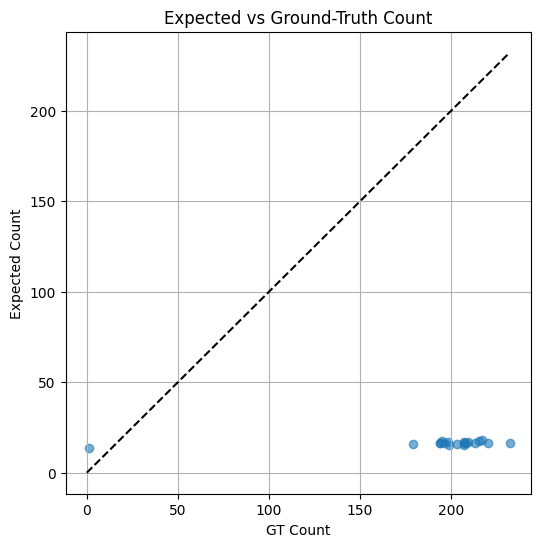

In [22]:
exp_counts = []
gt_counts = []

for prefix in prefixes:
    s = load_sample(prefix)
    lam = s["lambda_pred"]
    lam_gt = s["lambda_gt"]

    H, W = lam.shape
    lam_norm = lam / (H * W)

    exp_counts.append(lam_norm.sum())
    gt_counts.append((lam_gt > 0).sum())

exp_counts = np.array(exp_counts)
gt_counts = np.array(gt_counts)

plt.figure(figsize=(6, 6))
plt.scatter(gt_counts, exp_counts, alpha=0.6)
plt.plot([0, max(gt_counts)], [0, max(gt_counts)], "k--")

plt.xlabel("GT Count")
plt.ylabel("Expected Count")
plt.title("Expected vs Ground-Truth Count")
plt.grid(True)
plt.show()

In [23]:
from ipywidgets import Dropdown

dropdown = Dropdown(options=prefixes, description="Sample:")
dropdown

Dropdown(description='Sample:', options=('iter_0000000_test_frame_000000_s0', 'iter_0000000_test_frame_000010_…

In [38]:
prefix = dropdown.value
sample = load_sample(prefix)

# idx = 140
# prefix = prefixes[idx]
# sample = load_sample(prefix)

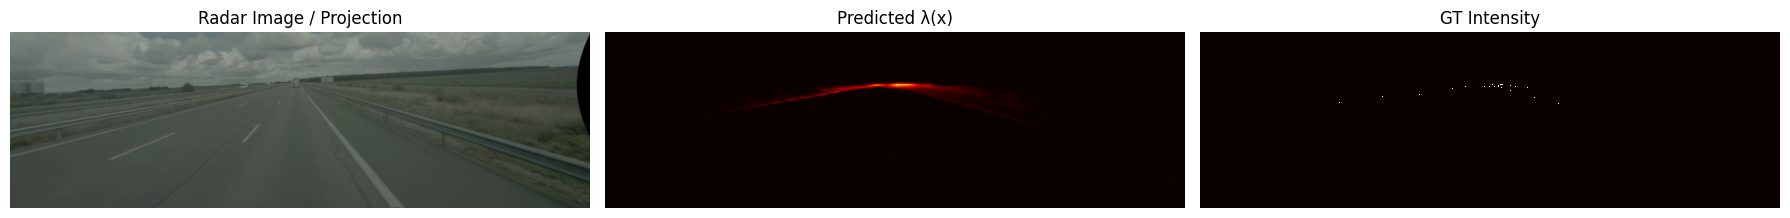

PPP Expected Count
-----------------------------
Expected count: 16.143
GT count: 220
Difference: -203.857


In [39]:
img = sample["img"]
lam = sample["lambda_pred"]
lam_gt = sample["lambda_gt"]

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

axs[0].imshow(img)
axs[0].set_title("Radar Image / Projection")

axs[1].imshow(lam)
axs[1].set_title("Predicted λ(x)")

# axs[2].imshow(lam_gt)
axs[2].imshow(lam_gt, interpolation="nearest")
axs[2].set_title("GT Intensity")

for ax in axs:
    ax.axis("off")

plt.tight_layout()
plt.show()

H, W = lam.shape
pixel_area = H * W

lam_norm = lam / pixel_area

expected_count = lam_norm.sum()
gt_count = (lam_gt > 0).sum()

print("PPP Expected Count")
print("-----------------------------")
print(f"Expected count: {expected_count:.3f}")
print(f"GT count: {gt_count:.0f}")
print(f"Difference: {expected_count - gt_count:+.3f}")

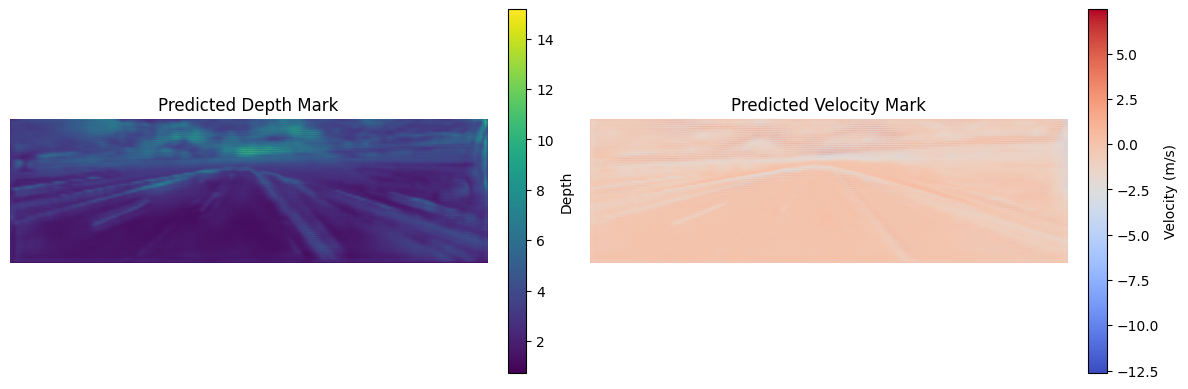

In [40]:
depth = sample["depth_pred"]
vel   = sample["vel_pred"]

if depth is None and vel is None:
    print("No depth or velocity prediction available.")
else:
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))

    # -----------------------
    # Depth
    # -----------------------
    if depth is not None:
        im0 = axs[0].imshow(depth, cmap="viridis")
        axs[0].set_title("Predicted Depth Mark")
        axs[0].axis("off")
        cbar0 = fig.colorbar(im0, ax=axs[0], fraction=0.046, pad=0.04)
        cbar0.set_label("Depth")
    else:
        axs[0].set_title("No Depth Prediction")
        axs[0].axis("off")

    # -----------------------
    # Velocity
    # -----------------------
    if vel is not None:
        im1 = axs[1].imshow(vel, cmap="coolwarm")
        axs[1].set_title("Predicted Velocity Mark")
        axs[1].axis("off")
        cbar1 = fig.colorbar(im1, ax=axs[1], fraction=0.046, pad=0.04)
        cbar1.set_label("Velocity (m/s)")
    else:
        axs[1].set_title("No Velocity Prediction")
        axs[1].axis("off")

    plt.tight_layout()
    plt.show()


### Point Placement via Thinning of a Homogeneous Poisson Point Process

In [68]:
import numpy as np

def sample_ppp_by_thinning(
    lambda_grid: np.ndarray,
    *,
    pixel_area: float,
    rng: np.random.Generator | None = None,
):
    """
    Sample an inhomogeneous PPP using thinning from a homogeneous PPP.

    Parameters
    ----------
    lambda_grid : (H, W) array
        Intensity lambda(x) evaluated on a pixel grid (nonnegative).
    pixel_area : float
        Area represented by one pixel (must match how expected counts were computed).
    rng : np.random.Generator
        Random generator.

    Returns
    -------
    points_xy : (N, 2) array
        Accepted points in image coordinates (x, y).
    N : int
        Number of accepted points.
    lambda_max : float
        Max intensity used for thinning.
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    assert np.all(lam >= 0)

    H, W = lam.shape

    lambda_max = lam.max()
    if lambda_max == 0:
        return np.zeros((0, 2)), 0, 0.0

    # Total intensity of homogeneous PPP
    area_total = H * W * pixel_area
    Lambda_hom = lambda_max * area_total

    # 1) sample homogeneous PPP
    # N_prop is the number of proposal points in the homogeneous Poisson point process 
    # with intensity lambda_max over the whole image domain.
    N_prop = rng.poisson(Lambda_hom)

    if N_prop == 0:
        return np.zeros((0, 2)), 0, lambda_max

    # uniform proposal locations over image
    xs = rng.random(N_prop) * W
    ys = rng.random(N_prop) * H

    # Converts continuous x-coordinates to integers, Equivalent to floor(xs) for 
    # nonnegative values, Maps point → pixel index
    xi = np.clip(xs.astype(int), 0, W - 1)
    yi = np.clip(ys.astype(int), 0, H - 1)

    # 2) thinning step
    # For each proposed point (xi,yi), we evaluate the predicted intensity at its location 
    # by looking up the corresponding pixel in lambda_grid.
    lam_x = lam[yi, xi]
    accept_prob = lam_x / lambda_max

    # his performs independent Bernoulli trials for all proposal points:
    # Each proposal point is kept if its random number is smaller than its acceptance probability
    keep = rng.random(N_prop) < accept_prob

    # Finally, we collect the coordinates of all accepted points.
    points_xy = np.stack([xs[keep], ys[keep]], axis=1)

    return points_xy, points_xy.shape[0], float(lambda_max), N_prop



def visualize_gt_ppp_heatmap(
    img,
    gt_points_xy,
    ppp_points_xy,
    lambda_grid,
    *,
    point_size=6,
    cmap="viridis",
):
    fig, axes = plt.subplots(
        3, 1,
        figsize=(12, 14),
        sharex=True,
        sharey=True
    )

    # --- Ground Truth ---
    axes[0].imshow(img)
    if len(gt_points_xy) > 0:
        axes[0].scatter(
            gt_points_xy[:, 0],
            gt_points_xy[:, 1],
            s=point_size,
            c="lime",
            alpha=0.9,
        )
    axes[0].set_title(f"Ground Truth (N={len(gt_points_xy)})")
    axes[0].axis("off")

    # --- PPP result ---
    axes[1].imshow(img)
    if len(ppp_points_xy) > 0:
        axes[1].scatter(
            ppp_points_xy[:, 0],
            ppp_points_xy[:, 1],
            s=point_size,
            c="red",
            alpha=0.8,
        )
    axes[1].set_title(f"PPP point cloud (N={len(ppp_points_xy)})")
    axes[1].axis("off")

    # --- Heatmap ---
    im = axes[2].imshow(lambda_grid, cmap=cmap)
    axes[2].set_title("Predicted intensity λ(x)")
    axes[2].axis("off")
    plt.colorbar(im, ax=axes[2], fraction=0.046)

    plt.tight_layout()
    plt.show()

def extract_gt_points_from_mask(mask):
    # turns mask into x,y coordinates
    ys, xs = np.where(mask > 0)
    return np.stack([xs + 0.5, ys + 0.5], axis=1)


Lambda max: 6469.38037109375
Accepted points: 13
Expected count: 16.143169733196984
GT count: 220
Acceptance rate: 0.0020123839009287925


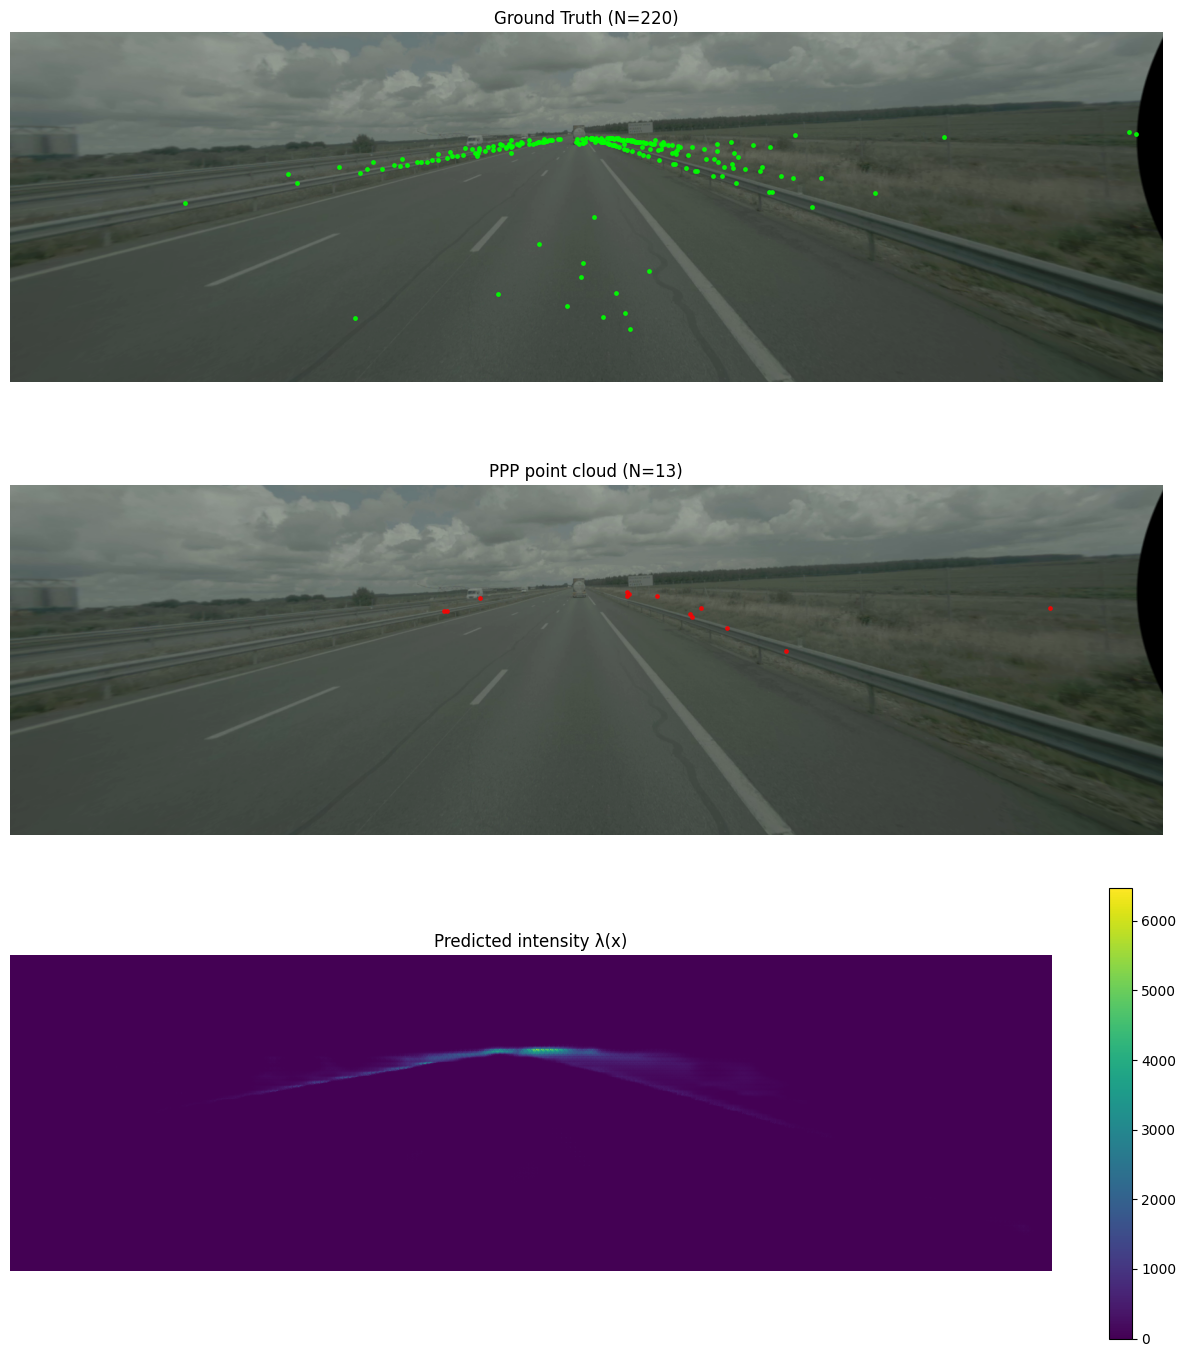

In [69]:
s = load_sample(prefix)

# PPP thinning
H, W = s["lambda_pred"].shape
pixel_area = 1.0 / (H * W) # i.e. the pixel_area = 1 pixel

ppp_points, N, lam_max, N_prop = sample_ppp_by_thinning(
    s["lambda_pred"],
    pixel_area=pixel_area,
)

print("Lambda max:", lam_max)
print("Accepted points:", N)
print("Expected count:", s["meta"]["ppp_diagnostics"]["expected_count_full"])
print("GT count:", s["meta"]["ppp_diagnostics"]["gt_count_full"])
print("Acceptance rate:", N / max(N_prop, 1))

# GT points (from GT mask / count map)
gt_points = extract_gt_points_from_mask(s["lambda_gt"])

visualize_gt_ppp_heatmap(
    img=s["img"],
    gt_points_xy=gt_points,
    ppp_points_xy=ppp_points,
    lambda_grid=s["lambda_pred"],
)


### Blockwise Bernoulli Point Placement via Empty Space Probabilities

In [ ]:
def sample_points_block_bernoulli(
    lambda_grid: np.ndarray,
    *,
    block_size: int = 8,
    pixel_area: float = 1.0,
    placement: str = "weighted",   # "weighted" or "uniform"
    # Controls where inside an active block the point is placed:
    # "uniform" → uniform in block area, "weighted" → proportional to λ inside the block
    rng: np.random.Generator | None = None,
    # Optional random number generator for reproducibility.
):
    """
    Block/Bernoulli approximation of a PPP:
      For each block A:
        Λ_A = sum_{A} λ * pixel_area
        Activate block with p_A = 1 - exp(-Λ_A)
      If active, place exactly one point in A.

    Returns
    -------
    points_xy : (N,2) array in image coords
    stats : dict with diagnostics
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    assert np.all(np.isfinite(lam)), "lambda_grid contains NaN/Inf."
    assert np.all(lam >= 0), "lambda_grid contains negative values."

    H, W = lam.shape
    bs = int(block_size)
    assert bs > 0

    points = []
    num_blocks = 0
    num_active = 0
    expected_blocks_active = 0.0  # sum p_A

    # Iterate over the image in non-overlapping block_size × block_size blocks.
    for y0 in range(0, H, bs):
        for x0 in range(0, W, bs):
            # Handle boundary blocks at the image edges.
            y1 = min(y0 + bs, H)
            x1 = min(x0 + bs, W)
            num_blocks += 1

            # Expected count in block
            block = lam[y0:y1, x0:x1]
            Lambda_A = block.sum() * pixel_area

            if Lambda_A <= 0:
                continue
            
            # probability that there is at least one dot in the square (Bernoulli experiment)
            pA = 1.0 - np.exp(-Lambda_A)
            # we track the expected number of blocks that should become active (sanity check)
            expected_blocks_active += pA

            # Perform Bernoulli experiment
            if rng.random() >= pA:
                # block inactive
                continue
            
            # block active
            num_active += 1
            
            # Placement of the point in the block
            hB, wB = block.shape

            if placement == "uniform" or block.sum() == 0:
                # uniform point inside the block
                x = x0 + rng.random() * wB
                y = y0 + rng.random() * hB

            elif placement == "weighted":
                # choose a pixel proportional to λ inside the block, then jitter within pixel
                probs = (block / block.sum()).ravel()
                idx = rng.choice(probs.size, p=probs)
                by, bx = divmod(idx, wB)
                x = x0 + bx + rng.random()
                y = y0 + by + rng.random()

            else:
                raise ValueError("placement must be 'weighted' or 'uniform'")

            points.append([x, y])

    points_xy = np.asarray(points, dtype=np.float64) if points else np.zeros((0, 2), dtype=np.float64)

    stats = dict(
        block_size=bs,
        placement=placement,
        num_blocks=num_blocks,
        num_active_blocks=num_active,
        expected_active_blocks=float(expected_blocks_active),
        num_points=int(points_xy.shape[0]),
    )
    return points_xy, stats

In [71]:
H, W = s["lambda_pred"].shape
pixel_area = 1.0 / (H * W)

block_points, stats = sample_points_block_bernoulli(
    s["lambda_pred"],
    block_size=8,
    pixel_area=pixel_area,
    placement="weighted",
)

print(stats)

{'block_size': 8, 'placement': 'weighted', 'num_blocks': 15232, 'num_active_blocks': 17, 'expected_active_blocks': 15.615044373130386, 'num_points': 17}


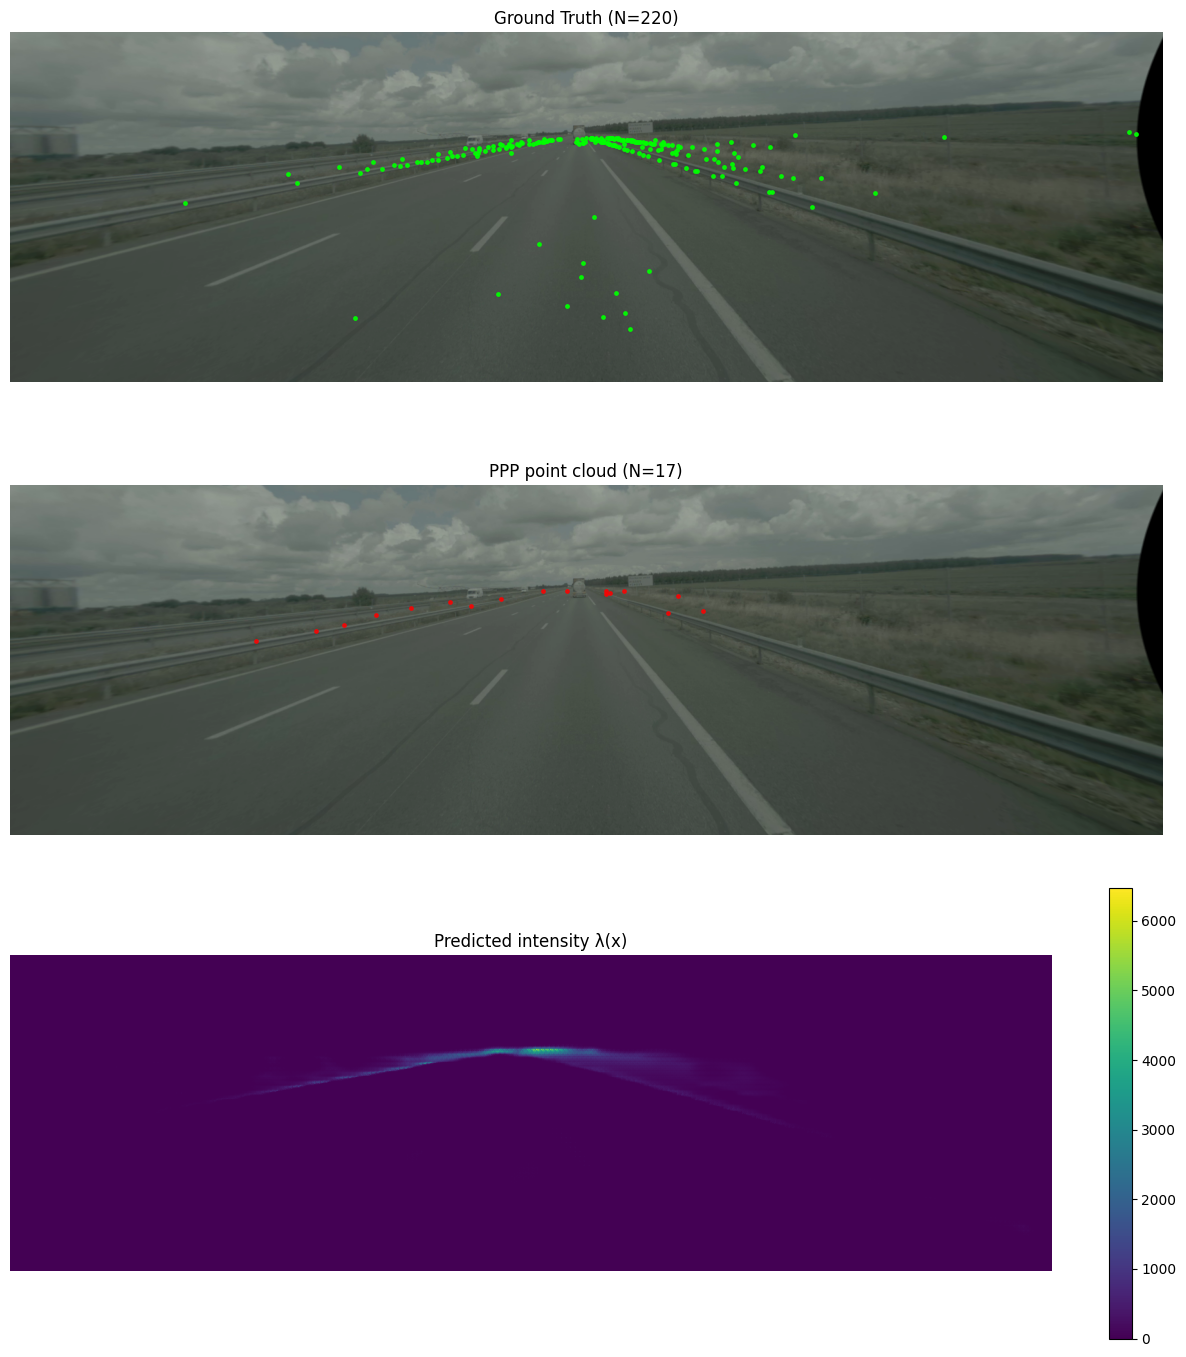

In [72]:
gt_points = extract_gt_points_from_mask(s["lambda_gt"])

visualize_gt_ppp_heatmap(
    img=s["img"],
    gt_points_xy=gt_points,
    ppp_points_xy=block_points,
    lambda_grid=s["lambda_pred"],
)